<a href="https://colab.research.google.com/github/AnnesaAD05/Python-Projects-Informatics-1st-year-annesa/blob/main/%F0%9F%93%82_Smart_File_Organizer_%26_Investigator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📂 Smart File Organizer & Investigator



In [7]:
import os
import hashlib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import shutil

class FileInvestigator:
    def __init__(self, target_folder):
        self.target_folder = Path(target_folder)
        self.files_df = pd.DataFrame()
        self.duplicates = {}

    def get_file_hash(self, file_path, block_size=65536):
        """Generate SHA-256 hash for a file to accurately identify duplicates."""
        hasher = hashlib.sha256()
        try:
            with open(file_path, 'rb') as f:
                for block in iter(lambda: f.read(block_size), b''):
                    hasher.update(block)
            return hasher.hexdigest()
        except Exception as e:
            return None

    def scan_files(self):
        """1. Smart File Scanner: Gather metadata of all files in target folder."""
        file_data = []
        for root, _, files in os.walk(self.target_folder):
            for file in files:
                file_path = Path(root) / file
                try:
                    size = file_path.stat().st_size
                    ext = file_path.suffix.lower() or 'no_extension'
                    file_data.append({
                        'filename': file,
                        'path': str(file_path),
                        'extension': ext,
                        'size_bytes': size,
                        'size_mb': round(size / (1024 * 1024), 6) # Higher precision for small dummy files
                    })
                except Exception as e:
                    continue

        self.files_df = pd.DataFrame(file_data)
        print(f"🔍 Scanned {len(self.files_df)} files in '{self.target_folder}'.")
        return self.files_df

    def detect_duplicates(self):
        """2. Duplicate Detector: Identifies duplicates via hashing."""
        if self.files_df.empty:
            print("Please scan files first!")
            return {}

        print("🧬 Analyzing file hashes to identify duplicate groups...")
        hashes = []
        for idx, row in self.files_df.iterrows():
            hashes.append(self.get_file_hash(row['path']))

        self.files_df['sha256'] = hashes

        # Group identical hashes
        dup_groups = self.files_df[self.files_df['sha256'].notna()].groupby('sha256')
        self.duplicates = {}

        for file_hash, group in dup_groups:
            if len(group) > 1:
                self.duplicates[file_hash] = group[['filename', 'path', 'size_mb']].to_dict(orient='records')

        print(f"👥 Found {len(self.duplicates)} groups of duplicate files.")
        return self.duplicates

    def plot_storage_analytics(self):
        """3. Storage Analytics: Computes and plots distribution of storage."""
        if self.files_df.empty:
            print("No data to analyze.")
            return

        # Use bytes if total MB is near 0, to avoid NaN issues with dummy files
        total_mb = self.files_df['size_mb'].sum()
        value_col = 'size_bytes' if total_mb < 0.01 else 'size_mb'
        unit_label = 'Bytes' if value_col == 'size_bytes' else 'MB'

        analytics = self.files_df.groupby('extension').agg(
            file_count=('filename', 'count'),
            total_size_val=(value_col, 'sum')
        ).reset_index().sort_values(by='total_size_val', ascending=False)

        # Visualizations safely ignoring division-by-zero problems
        if analytics['total_size_val'].sum() == 0:
            analytics['total_size_val'] = 1 # Temporary fallback mapping

        plt.figure(figsize=(12, 5))

        plt.subplot(1, 2, 1)
        sns.barplot(data=analytics.head(8), x='extension', y='total_size_val', hue='extension', palette='viridis', legend=False)
        plt.title(f'Top Storage Consuming Extensions ({unit_label})')
        plt.xticks(rotation=45)
        plt.ylabel(f'Size ({unit_label})')

        plt.subplot(1, 2, 2)
        plt.pie(analytics.head(5)['total_size_val'], labels=analytics.head(5)['extension'], autopct='%1.1f%%', startangle=140)
        plt.title('Distribution of Top 5 Extensions')

        plt.tight_layout()
        plt.show()

        return analytics

    def organize_files(self, dry_run=True):
        """4. Automatic Organizer: Categorizes files into folders."""
        category_map = {
            '.pdf': 'Documents', '.docx': 'Documents', '.txt': 'Documents', '.xlsx': 'Documents',
            '.png': 'Images', '.jpg': 'Images', '.jpeg': 'Images', '.gif': 'Images',
            '.mp4': 'Videos', '.mkv': 'Videos', '.avi': 'Videos',
            '.zip': 'Archives', '.tar': 'Archives', '.gz': 'Archives', '.rar': 'Archives'
        }

        actions = []
        for idx, row in self.files_df.iterrows():
            ext = row['extension']
            category = category_map.get(ext, 'Others')
            dest_dir = self.target_folder / category
            dest_path = dest_dir / row['filename']

            actions.append({
                'filename': row['filename'],
                'from': row['path'],
                'to': str(dest_path),
                'category': category
            })

            if not dry_run:
                dest_dir.mkdir(exist_ok=True)
                shutil.move(row['path'], dest_path)

        mode = "[DRY RUN - PREVIEW ONLY]" if dry_run else "[LIVE MOVE]"
        print(f"\n🚀 {mode} Organized files into: Documents, Images, Videos, Archives, Others.")
        return pd.DataFrame(actions)

    def generate_report(self, output_path="system_investigation.md"):
        """5. Investigation Report Generator."""
        total_files = len(self.files_df)
        total_size = self.files_df['size_mb'].sum()

        report_content = f"""# 🕵️‍♂️ Investigation Report: File System Audit

## 📊 Storage Summary
- **Total Scanned Files**: {total_files}
- **Total Storage Space**: {total_size:.6f} MB

## 🗂️ Extension Analytics
"""
        analytics = self.files_df.groupby('extension').agg(
            count=('filename', 'count'),
            size_mb=('size_mb', 'sum')
        ).to_markdown()

        report_content += analytics + "\n\n## 👥 Duplicate Groups Identified\n"

        if not self.duplicates:
            report_content += "No duplicates found! Excellent file hygiene.\n"
        else:
            for i, (f_hash, items) in enumerate(self.duplicates.items(), 1):
                report_content += f"### Group {i} (Hash: {f_hash[:12]}...)\n"
                report_content += f"- **File Size**: {items[0]['size_mb']:.6f} MB\n"
                report_content += "- **Identical Locations**:\n"
                for item in items:
                    report_content += f"  - `{item['path']}`\n"
                report_content += "\n"

        with open(output_path, 'w') as f:
            f.write(report_content)

        print(f"📝 Investigation report written successfully to '{output_path}'")

### Live Demonstration & Testing
Let's generate dummy test files of diverse formats inside a directory to demonstrate our script in action, then run the entire investigation pipeline.

🔍 Scanned 6 files in 'sandbox_downloads'.
🧬 Analyzing file hashes to identify duplicate groups...
👥 Found 2 groups of duplicate files.

--- Storage Analysis ---


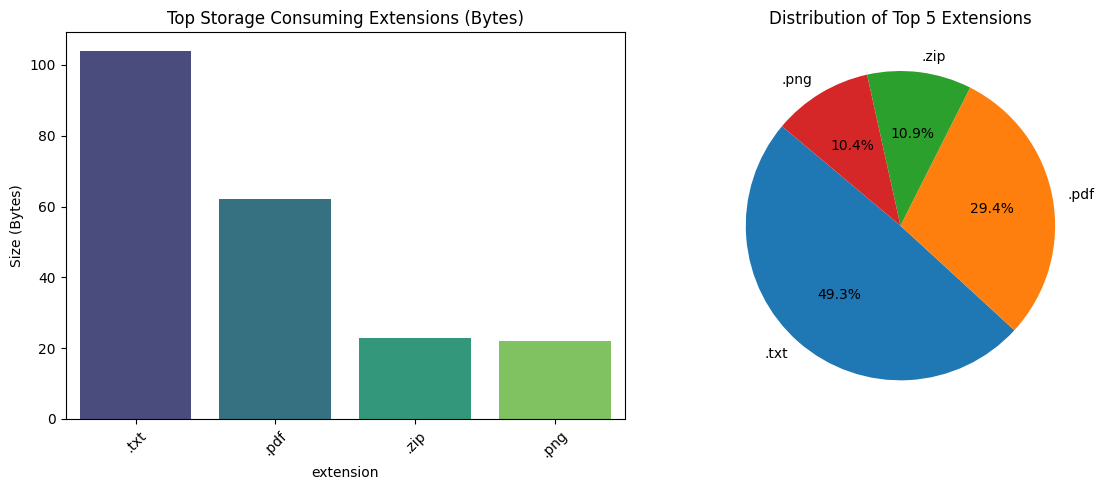


🚀 [DRY RUN - PREVIEW ONLY] Organized files into: Documents, Images, Videos, Archives, Others.


,filename,from,to,category
0,archive.zip,sandbox_downloads/archive.zip,sandbox_downloads/Archives/archive.zip,Archives
1,vacation_photo.png,sandbox_downloads/vacation_photo.png,sandbox_downloads/Images/vacation_photo.png,Images
2,invoice_2026_copy.pdf,sandbox_downloads/invoice_2026_copy.pdf,sandbox_downloads/Documents/invoice_2026_copy.pdf,Documents
3,notes.txt,sandbox_downloads/notes.txt,sandbox_downloads/Documents/notes.txt,Documents
4,invoice_2026.pdf,sandbox_downloads/invoice_2026.pdf,sandbox_downloads/Documents/invoice_2026.pdf,Documents
5,notes_backup.txt,sandbox_downloads/deep_folder/notes_backup.txt,sandbox_downloads/Documents/notes_backup.txt,Documents


📝 Investigation report written successfully to 'system_investigation.md'


In [8]:
from pathlib import Path

# 1. Create a dummy folder containing files, folders, and perfect duplicates
test_dir = Path("./sandbox_downloads")
test_dir.mkdir(exist_ok=True)

# Create some simulated dummy files
def create_file(path, content):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    with open(path, 'w') as f:
        f.write(content)

create_file(test_dir / "invoice_2026.pdf", "Invoice metadata standard #1039")
create_file(test_dir / "invoice_2026_copy.pdf", "Invoice metadata standard #1039")  # Duplicate
create_file(test_dir / "vacation_photo.png", "PNG_DATA_STREAM_XYZ123")
create_file(test_dir / "notes.txt", "Don't forget to pack sunscreen and travel documents.")
create_file(test_dir / "deep_folder/notes_backup.txt", "Don't forget to pack sunscreen and travel documents.")  # Duplicate
create_file(test_dir / "archive.zip", "COMPRESSED_ARCHIVE_DATA")

# 2. Run the Investigator
investigator = FileInvestigator(test_dir)

# Step 1 & 2: Scan & Detect Duplicates
investigator.scan_files()
investigator.detect_duplicates()

# Step 3: Analytics
print("\n--- Storage Analysis ---")
investigator.plot_storage_analytics()

# Step 4: Organizer (Dry Run Preview)
preview_df = investigator.organize_files(dry_run=True)
display(preview_df.head(10))

# Step 5: Generate Report
investigator.generate_report("system_investigation.md")

### Read the Generated Investigation Report

In [9]:
# Displaying the exported investigator report
with open("system_investigation.md", "r") as f:
    print(f.read())

# 🕵️‍♂️ Investigation Report: File System Audit

## 📊 Storage Summary
- **Total Scanned Files**: 6
- **Total Storage Space**: 0.000203 MB

## 🗂️ Extension Analytics
| extension   |   count |   size_mb |
|:------------|--------:|----------:|
| .pdf        |       2 |   6e-05   |
| .png        |       1 |   2.1e-05 |
| .txt        |       2 |   0.0001  |
| .zip        |       1 |   2.2e-05 |

## 👥 Duplicate Groups Identified
### Group 1 (Hash: 359164dc8c1b...)
- **File Size**: 0.000030 MB
- **Identical Locations**:
  - `sandbox_downloads/invoice_2026_copy.pdf`
  - `sandbox_downloads/invoice_2026.pdf`

### Group 2 (Hash: f1ac0acb9321...)
- **File Size**: 0.000050 MB
- **Identical Locations**:
  - `sandbox_downloads/notes.txt`
  - `sandbox_downloads/deep_folder/notes_backup.txt`


